# Entrega 3 · Modelado predictivo del ROI de una película

**Pregunta del modelo:** con lo que se sabe *antes del estreno* (presupuesto, género, idioma, duración, productora, elenco, fecha), ¿podemos anticipar cuántas veces recupera una película lo que costó?

**Qué cambió desde la Entrega 2**
1. **Dataset:** se volvió a correr el DAG en modo `full`. El notebook lee el CSV más reciente de `include/output/` (`movies_<fecha>.csv`), que genera cada integrante con su propia corrida y no se sube a git. Las salidas guardadas son de la corrida del 24/10/2026: **9.940 películas**, porque 60 no se pudieron bajar por cortes de conexión con TMDb. Si se corre con otro CSV, los números van a variar un poco.
2. **Alcance:** se agregan filtros de montos imposibles (`budget` y `revenue` mayores o iguales a 10.000 USD) y se excluyen las películas de 2026, que siguen en cartelera.
3. **Objetivo:** el ROI, pero se modela y se mide en escala logarítmica: $y = \log_{10}(\text{revenue}/\text{budget}) = \log_{10}(1 + \text{ROI})$. En la sección 3 se muestra por qué el MAE sobre el ROI crudo no sirve para elegir modelos.

El notebook corre de arriba a abajo. La semilla se define en la primera celda y se pasa a todo lo que la acepta.

In [1]:
# 1. Semilla, librerías y carga del dataset
SEED = 42

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

np.random.seed(SEED)
plt.style.use("default")
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", "{:.4f}".format)

from pathlib import Path

# Cada integrante usa el CSV de su propia corrida del DAG (include/output está en .gitignore).
# Se toma el más reciente: el nombre lleva la fecha, así que el mayor alfabético es el último.
CSV_PATH = max(Path("include/output").glob("movies_*.csv"))
df = pd.read_csv(CSV_PATH)
if len(df) < 7_000:
    raise ValueError(f"{CSV_PATH} tiene {len(df):,} filas: parece una corrida en modo subset. "
                     "Correr el DAG con mode=full antes de ejecutar este notebook.")
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
print(f"Dataset: {CSV_PATH} -> {df.shape[0]:,} filas x {df.shape[1]} columnas")

scikit-learn 1.9.1 | pandas 3.1.0
Dataset: include/output/movies_2026-10-24.csv -> 9,940 filas x 18 columnas


## 1. Alcance: qué películas entran

Tres filtros. Todos se deciden con información que existe **antes** de mirar el resultado del modelo:

| Filtro | Por qué |
|---|---|
| `budget > 0` y `revenue > 0` | Sin los dos montos no hay ROI. No se imputa: inventar un presupuesto es inventar el objetivo. |
| `budget >= 10.000 USD` | Montos de 1, 2 o 7 dólares son errores de carga de TMDb (por ejemplo, *East of Eden* con presupuesto 2). Es un filtro sobre una columna de entrada. |
| `revenue >= 10.000 USD` | Mismo umbral para la recaudación. Lo encontramos al leer los errores del modelo: *Society of the Snow* figura con 1.281 USD y *Memoir of a Snail* con 7 USD. Son estrenos de streaming sin taquilla real o errores de carga, no fracasos. Este filtro toca el objetivo, así que se limita a montos imposibles: saca muy pocas filas y no recorta la cola de éxitos ni de fracasos reales. |
| `release_year < 2026` | Las películas de 2026 siguen en cartelera: su `revenue` está incompleto y su ROI saldría subestimado. |

In [2]:
# 2. Filtros de alcance, contando cuántas filas quita cada uno
pasos = [("Dataset completo", df)]
d = df[(df["budget"] > 0) & (df["revenue"] > 0)]
pasos.append(("Con budget y revenue > 0", d))
d = d[d["budget"] >= 10_000]
pasos.append(("Con budget >= 10.000 USD", d))
d = d[d["revenue"] >= 10_000]
pasos.append(("Con revenue >= 10.000 USD", d))
d = d[d["release_year"] < 2026]
pasos.append(("Estrenadas antes de 2026", d))

for nombre, tabla in pasos:
    print(f"{nombre:<28} {len(tabla):>6,} filas")

data = d.copy()
data["roi"] = (data["revenue"] - data["budget"]) / data["budget"]
data["y"] = np.log10(data["revenue"] / data["budget"])  # = log10(1 + ROI)

Dataset completo              9,940 filas
Con budget y revenue > 0      6,528 filas
Con budget >= 10.000 USD      6,522 filas
Con revenue >= 10.000 USD     6,500 filas
Estrenadas antes de 2026      6,391 filas


## 2. El objetivo: por qué ROI en escala logarítmica

El ROI tiene una cola enorme: la mediana ronda 1,4 (la película recauda 2,4 veces lo que costó), pero hay casos como *Paranormal Activity* con ROI de casi 13.000. En escala lineal, esos pocos casos deciden cualquier promedio. En escala log10, un punto de error significa "le erré por un factor de 10" sin importar si la película es chica o grande.

count    6391.0000
mean        7.8837
std       171.8556
min        -0.9993
25%         0.1432
50%         1.4017
75%         3.7002
99%        65.9755
max     12889.3867

Las 5 películas con mayor ROI:
                  title  release_year      budget        revenue        roi
    Paranormal Activity          2009  15000.0000 193355800.0000 12889.3867
The Blair Witch Project          1999  60000.0000 248639099.0000  4142.9850
           Fist of Fury          1972 100000.0000 100000000.0000   999.0000
  The Birth of a Nation          1915 100000.0000 100000000.0000   999.0000
  The Brothers McMullen          1995  25000.0000  19326506.0000   772.0602


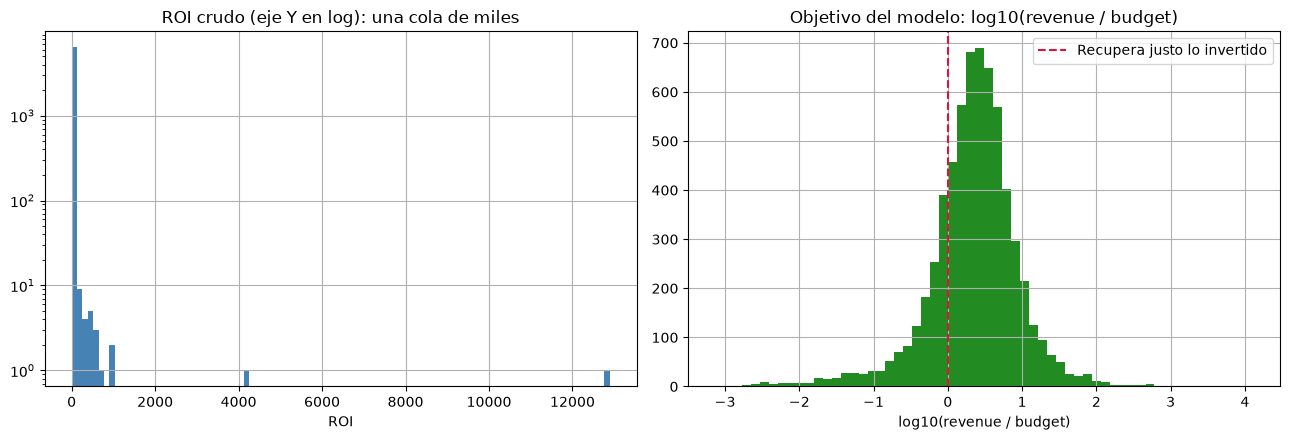

In [3]:
# 3. Distribución del ROI crudo vs. log10(revenue/budget)
print(data["roi"].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).to_string())
print("\nLas 5 películas con mayor ROI:")
print(data.nlargest(5, "roi")[["title", "release_year", "budget", "revenue", "roi"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(data["roi"], bins=100, color="steelblue")
axes[0].set_yscale("log")
axes[0].set_title("ROI crudo (eje Y en log): una cola de miles")
axes[0].set_xlabel("ROI")
axes[1].hist(data["y"], bins=60, color="forestgreen")
axes[1].axvline(0, color="crimson", linestyle="--", label="Recupera justo lo invertido")
axes[1].set_title("Objetivo del modelo: log10(revenue / budget)")
axes[1].set_xlabel("log10(revenue / budget)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Las cuatro decisiones antes del primer modelo

### 3.1 Métrica: MAE sobre $\log_{10}(\text{revenue}/\text{budget})$

- **Qué error es caro:** para una productora, equivocarse en el *múltiplo* de recuperación. Prever que una película triplica su costo y que la recupere a medias es el mismo error relativo en una de 1 millón que en una de 200 millones.
- **Cómo se lee:** un MAE de 0,40 significa que, en promedio, la predicción del múltiplo `revenue/budget` está errada por un factor de $10^{0,40} \approx 2,5$ (para arriba o para abajo).
- **Por qué no MAE sobre el ROI crudo**, que era la propuesta inicial: lo probamos (celda siguiente). Una sola película (*Paranormal Activity*, ROI ≈ 12.900) cae en un fold y lleva el MAE de ese fold a más de 17, cuando los otros dan 3–7. Con un desvío entre folds tan grande, ningún modelo se distingue del piso: la métrica mide en qué fold cayó el outlier, no qué modelo es mejor.
- **Por qué no RMSE ni R²:** el RMSE eleva al cuadrado y es todavía más sensible a esa cola. El R² no tiene unidades que se puedan explicar a un productor.

### 3.2 Piso: `DummyRegressor(strategy="median")`
Predice siempre la mediana del entrenamiento sin mirar ninguna columna. Es el número contra el que se lee todo lo demás.

### 3.3 Validación que imita el uso
El modelo se usaría para películas **futuras**, con lo aprendido de las pasadas. Por eso:
1. Las películas se ordenan por fecha de estreno (`release_year`, `release_month`).
2. El **20% más reciente** se separa como test y se mira **una sola vez**, al final.
3. Sobre el 80% restante, `TimeSeriesSplit(5)`: cada fold entrena con el pasado y valida con el período siguiente.

Además, las filas **no son independientes**: la misma productora, el mismo director o la misma franquicia se repiten. Un corte al azar mete películas de 2015 en el entrenamiento para predecir una de 2012, y deja secuelas de los dos lados. En la sección 5 se mide cuánto cambia el número si se corta al azar.

### 3.4 Todo adentro de un pipeline
Logaritmos, imputación, escalado y one-hot van dentro de un `ColumnTransformer` que se ajusta en cada fold solo con el entrenamiento de ese fold. Antes de partir solo se calcula el objetivo `y`, que es una cuenta fila por fila y no usa información de otras filas.

In [4]:
# 4. Prueba descartada: MAE sobre el ROI crudo (para justificar la métrica)
datos_ord = data.sort_values(["release_year", "release_month", "movie_id"]).reset_index(drop=True)
n_test = int(len(datos_ord) * 0.20)
train, test = datos_ord.iloc[:-n_test], datos_ord.iloc[-n_test:]

tss = TimeSeriesSplit(n_splits=5)
dummy_crudo = cross_validate(DummyRegressor(strategy="median"), train, train["roi"], cv=tss,
                             scoring="neg_mean_absolute_error")
mae_crudo = -dummy_crudo["test_score"]
print("Piso con MAE sobre ROI crudo, por fold:", np.round(mae_crudo, 2))
print(f"Media {mae_crudo.mean():.2f} | desvío {mae_crudo.std():.2f}")
for i, (_, idx_val) in enumerate(tss.split(train)):
    fila = train.iloc[idx_val].nlargest(1, "roi").iloc[0]
    print(f"  Fold {i + 1}: mayor ROI = {fila['roi']:>9,.1f} ({fila['title']}, {fila['release_year']})")

Piso con MAE sobre ROI crudo, por fold: [ 4.6   7.25  3.84 17.8   4.3 ]
Media 7.56 | desvío 5.26
  Fold 1: mayor ROI =     772.1 (The Brothers McMullen, 1995)
  Fold 2: mayor ROI =   4,143.0 (The Blair Witch Project, 1999)
  Fold 3: mayor ROI =     454.7 (Open Water, 2004)
  Fold 4: mayor ROI =  12,889.4 (Paranormal Activity, 2009)
  Fold 5: mayor ROI =     555.8 (Mr. Six, 2015)


## 4. Partición temporal y columnas

In [5]:
# 5. Qué años cubre cada parte de la validación
print(f"Entrenamiento: {len(train):,} películas ({train['release_year'].min()}-{train['release_year'].max()})")
print(f"Test (20% más reciente, se mira una vez): {len(test):,} películas "
      f"({test['release_year'].min()}-{test['release_year'].max()})\n")
filas = []
for i, (idx_tr, idx_val) in enumerate(tss.split(train)):
    filas.append({
        "fold": i + 1,
        "entrena": f"{train.iloc[idx_tr]['release_year'].min()}-{train.iloc[idx_tr]['release_year'].max()}",
        "n_entrena": len(idx_tr),
        "valida": f"{train.iloc[idx_val]['release_year'].min()}-{train.iloc[idx_val]['release_year'].max()}",
        "n_valida": len(idx_val),
    })
print(pd.DataFrame(filas).to_string(index=False))

Entrenamiento: 5,113 películas (1915-2017)
Test (20% más reciente, se mira una vez): 1,278 películas (2017-2025)

 fold   entrena  n_entrena    valida  n_valida
    1 1915-1988        853 1988-1997       852
    2 1915-1997       1705 1997-2003       852
    3 1915-2003       2557 2003-2008       852
    4 1915-2008       3409 2008-2012       852
    5 1915-2012       4261 2012-2017       852


| Columna | Rol | Tratamiento dentro del pipeline |
|---|---|---|
| `budget` | Entra | `log10(1 + x)` y escalado. Se conoce antes de filmar. |
| `director_popularity`, `lead_actor_popularity`, `co_star_popularity` | Entran, **bajo sospecha** | `log10(1 + x)` y escalado. Ver sección 8: TMDb da la popularidad *de hoy*, no la previa al rodaje. |
| `runtime`, `release_year` | Entran | 0 se trata como faltante, se imputa con la mediana y se escala. |
| `original_language`, `primary_genre`, `secondary_genre`, `release_month`, `release_day_of_week` | Entran | One-hot; las categorías con menos de 20 películas se agrupan en "otras". |
| `primary_production_company`, `co_production_company` | Entran | One-hot de las productoras con 30 o más películas; el resto, "otras". |
| `revenue` | **Sale** | Es parte del objetivo: fuga directa. |
| `vote_average`, `vote_count` | **Salen** | Existen después del estreno. Se usan solo al final, para auditar las predicciones. |
| `movie_id`, `title` | Salen | Identificadores, no describen la película. |

In [6]:
# 6. Columnas y preprocesamiento (se reajusta en cada fold)
COLS_LOG = ["budget", "director_popularity", "lead_actor_popularity", "co_star_popularity"]
COLS_NUM = ["runtime", "release_year"]
COLS_CAT = ["original_language", "primary_genre", "secondary_genre", "release_month", "release_day_of_week"]
COLS_PROD = ["primary_production_company", "co_production_company"]
FEATURES = COLS_LOG + COLS_NUM + COLS_CAT + COLS_PROD


def log10_1p(X):
    return np.log10(1 + np.asarray(X, dtype=float))


def cero_a_nan(X):
    X = np.asarray(X, dtype=float).copy()
    X[X <= 0] = np.nan
    return X


def armar_preprocesador(excluir=()):
    # excluir: columnas que se dejan afuera (para la prueba de la sección 7)
    quedan = lambda cols: [c for c in cols if c not in excluir]
    bloques = [
        ("log", make_pipeline(FunctionTransformer(log10_1p, feature_names_out="one-to-one"),
                              StandardScaler()), quedan(COLS_LOG)),
        ("num", make_pipeline(FunctionTransformer(cero_a_nan, feature_names_out="one-to-one"),
                              SimpleImputer(strategy="median"), StandardScaler()), quedan(COLS_NUM)),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                              sparse_output=False), quedan(COLS_CAT)),
        ("prod", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                               sparse_output=False), quedan(COLS_PROD)),
    ]
    return ColumnTransformer([b for b in bloques if b[2]])


def modelo(estimador, excluir=()):
    return Pipeline([("pre", armar_preprocesador(excluir)), ("modelo", estimador)])


X_train, y_train = train[FEATURES], train["y"]
X_test, y_test = test[FEATURES], test["y"]
print(f"{len(FEATURES)} columnas de entrada -> "
      f"{armar_preprocesador().fit_transform(X_train).shape[1]} columnas después del one-hot")

13 columnas de entrada -> 111 columnas después del one-hot


## 5. Comparación de modelos

Todos con el mismo pipeline y los mismos 5 folds temporales, con sus valores por defecto razonables (el ajuste fino viene en la sección 6):

| Nivel | Modelo | Familia | Qué aporta |
|---|---|---|---|
| 0 | `DummyRegressor(median)` | Piso | Error a batir sin mirar columnas. |
| 1 | `Ridge` | Lineal | Modelo simple de referencia. Con L2 porque el one-hot genera columnas correlacionadas. |
| 2 | `RandomForestRegressor` | Árboles en paralelo (bagging) | No linealidades e interacciones (por ejemplo, género × presupuesto). |
| 3 | `HistGradientBoostingRegressor` | Boosting | Árboles en serie que corrigen el error del anterior. |

In [7]:
# 7. Validación cruzada temporal de los cuatro modelos
candidatos = {
    "Piso (mediana)": DummyRegressor(strategy="median"),
    "Ridge": modelo(Ridge(alpha=1.0)),
    "Random Forest": modelo(RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                  n_jobs=-1, random_state=SEED)),
    "HistGradientBoosting": modelo(HistGradientBoostingRegressor(random_state=SEED)),
}


def evaluar(modelos, cv):
    por_fold = {}
    for nombre, m in modelos.items():
        r = cross_validate(m, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
        por_fold[nombre] = -r["test_score"]
    return pd.DataFrame(por_fold, index=[f"fold {i + 1}" for i in range(cv.get_n_splits())])


folds_tss = evaluar(candidatos, tss)
resumen = pd.DataFrame({"MAE medio": folds_tss.mean(), "desvío": folds_tss.std(ddof=0)})
resumen["factor de error"] = 10 ** resumen["MAE medio"]
resumen["mejora vs piso"] = resumen.loc["Piso (mediana)", "MAE medio"] - resumen["MAE medio"]
print("=== MAE por fold (TimeSeriesSplit) ===")
print(folds_tss.round(4).to_string())
print("\n=== Resumen ===")
print(resumen.round(4).to_string())

=== MAE por fold (TimeSeriesSplit) ===
        Piso (mediana)  Ridge  Random Forest  HistGradientBoosting
fold 1          0.4909 0.3867         0.3857                0.4095
fold 2          0.4138 0.3755         0.3609                0.3814
fold 3          0.3895 0.3830         0.3567                0.3648
fold 4          0.4233 0.4367         0.4088                0.4141
fold 5          0.4136 0.4389         0.4253                0.4251

=== Resumen ===
                      MAE medio  desvío  factor de error  mejora vs piso
Piso (mediana)           0.4262  0.0342           2.6681          0.0000
Ridge                    0.4042  0.0277           2.5361          0.0220
Random Forest            0.3875  0.0266           2.4407          0.0387
HistGradientBoosting     0.3990  0.0224           2.5061          0.0272


### ¿El modelo complejo le gana al simple por más que el ruido?

El desvío de la tabla anterior mezcla dos cosas: lo que varía el modelo y lo **difícil que es cada período** (el fold que incluye 2020, con la pandemia, es más difícil para todos). Como todos los modelos se evalúan en los mismos folds, la comparación justa es **fold contra fold**: se resta el MAE de dos modelos en cada fold y se mira la media y el desvío de esa diferencia. Si la mejora media es mayor que su desvío, la mejora no es ruido.

In [8]:
# 8. Comparación pareada: diferencia de MAE fold por fold
def comparar(a, b):
    dif = folds_tss[a] - folds_tss[b]  # positivo = b se equivoca menos que a
    return {"comparación": f"{b} vs {a}", "mejora media": dif.mean(), "desvío de la mejora": dif.std(ddof=0),
            "folds que gana": f"{(dif > 0).sum()} de {len(dif)}", "supera el ruido": dif.mean() > dif.std(ddof=0)}


pares = [("Piso (mediana)", "Ridge"), ("Piso (mediana)", "Random Forest"),
         ("Piso (mediana)", "HistGradientBoosting"), ("Ridge", "Random Forest"),
         ("Ridge", "HistGradientBoosting"), ("HistGradientBoosting", "Random Forest")]
print(pd.DataFrame([comparar(a, b) for a, b in pares]).round(4).to_string(index=False))

                           comparación  mejora media  desvío de la mejora folds que gana  supera el ruido
               Ridge vs Piso (mediana)        0.0220               0.0464         3 de 5            False
       Random Forest vs Piso (mediana)        0.0387               0.0394         4 de 5            False
HistGradientBoosting vs Piso (mediana)        0.0272               0.0310         4 de 5            False
                Random Forest vs Ridge        0.0167               0.0098         5 de 5             True
         HistGradientBoosting vs Ridge        0.0052               0.0171         3 de 5            False
 Random Forest vs HistGradientBoosting        0.0115               0.0091         4 de 5             True


### ¿Qué pasaría si los pedazos se armaran al azar?

Misma comparación, pero con `KFold(5, shuffle=True)`: películas de todas las épocas mezcladas en entrenamiento y validación.

In [9]:
# 9. TimeSeriesSplit vs. KFold al azar
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds_kf = evaluar(candidatos, kf)
contraste = pd.DataFrame({
    "MAE temporal": folds_tss.mean(),
    "MAE al azar": folds_kf.mean(),
    "desvío al azar": folds_kf.std(ddof=0),
})
contraste["diferencia"] = contraste["MAE temporal"] - contraste["MAE al azar"]
print(contraste.round(4).to_string())

                      MAE temporal  MAE al azar  desvío al azar  diferencia
Piso (mediana)              0.4262       0.4177          0.0148      0.0085
Ridge                       0.4042       0.3878          0.0054      0.0163
Random Forest               0.3875       0.3714          0.0064      0.0161
HistGradientBoosting        0.3990       0.3760          0.0045      0.0230


## 6. Ajuste de hiperparámetros del modelo elegido

Se ajusta **Random Forest** (el criterio está en la guía del final). Grilla sobre los dos hiperparámetros que más controlan cuánto se ajusta a los datos:
- `min_samples_leaf`: cuántas películas como mínimo tiene cada hoja. Más alto, árboles más simples.
- `max_features`: qué fracción de las columnas mira cada corte. Más bajo, árboles más distintos entre sí.

Con los mismos 5 folds temporales y la tabla completa, no solo el ganador.

    min_samples_leaf  max_features  MAE medio  desvío
0                  5        0.3000     0.3807  0.0260
1                 10        0.3000     0.3817  0.0262
2                  1        0.3000     0.3824  0.0274
3                 20        0.3000     0.3831  0.0254
4                 10        0.6000     0.3840  0.0263
5                 20        0.6000     0.3840  0.0252
6                 40        0.6000     0.3850  0.0250
7                 20        1.0000     0.3852  0.0249
8                  5        0.6000     0.3854  0.0262
9                 40        0.3000     0.3855  0.0257
10                40        1.0000     0.3856  0.0244
11                10        1.0000     0.3862  0.0262
12                 1        0.6000     0.3863  0.0287
13                 5        1.0000     0.3875  0.0266
14                 1        1.0000     0.3889  0.0298

Mejor combinación: {'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 5}

                             comparación  mejora media

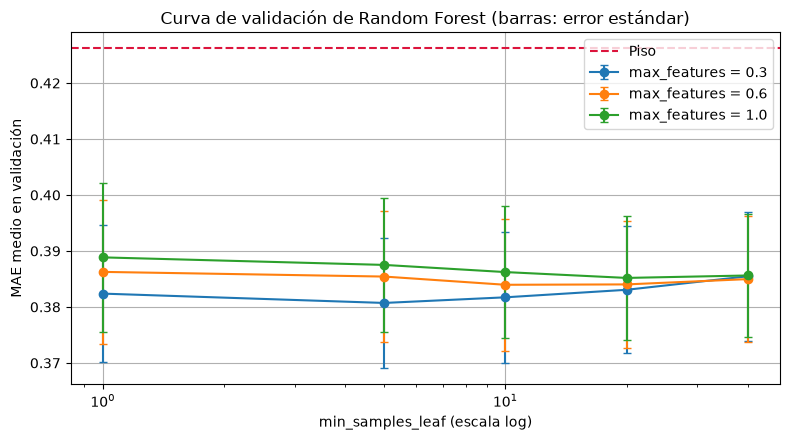

In [10]:
# 10. Grilla con validación temporal
grilla = GridSearchCV(
    modelo(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED)),
    param_grid={"modelo__min_samples_leaf": [1, 5, 10, 20, 40],
                "modelo__max_features": [0.3, 0.6, 1.0]},
    cv=tss, scoring="neg_mean_absolute_error",
)
grilla.fit(X_train, y_train)

tabla_grilla = pd.DataFrame(grilla.cv_results_)[
    ["param_modelo__min_samples_leaf", "param_modelo__max_features", "mean_test_score", "std_test_score"]
].rename(columns={"param_modelo__min_samples_leaf": "min_samples_leaf",
                  "param_modelo__max_features": "max_features",
                  "mean_test_score": "MAE medio", "std_test_score": "desvío"})
tabla_grilla["MAE medio"] *= -1
tabla_grilla = tabla_grilla.sort_values("MAE medio").reset_index(drop=True)
print(tabla_grilla.round(4).to_string())
print(f"\nMejor combinación: {grilla.best_params_}")

# Comparación pareada del modelo ajustado contra el piso y contra Ridge, fold por fold
mejor = grilla.best_index_
folds_tss["Random Forest ajustado"] = [-grilla.cv_results_[f"split{i}_test_score"][mejor] for i in range(5)]
print("\n" + pd.DataFrame([comparar("Piso (mediana)", "Random Forest ajustado"),
                           comparar("Ridge", "Random Forest ajustado")]).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
for mf, grupo in tabla_grilla.groupby("max_features"):
    grupo = grupo.sort_values("min_samples_leaf")
    ax.errorbar(grupo["min_samples_leaf"], grupo["MAE medio"], yerr=grupo["desvío"] / np.sqrt(5),
                marker="o", capsize=3, label=f"max_features = {mf}")
ax.axhline(resumen.loc["Piso (mediana)", "MAE medio"], color="crimson", linestyle="--", label="Piso")
ax.set_xscale("log")
ax.set_xlabel("min_samples_leaf (escala log)")
ax.set_ylabel("MAE medio en validación")
ax.set_title("Curva de validación de Random Forest (barras: error estándar)")
ax.legend()
plt.tight_layout()
plt.show()

**Clases desparejas:** no aplica. Es una regresión, no hay clases. Lo equivalente es la cola larga del objetivo, y eso se resolvió con la escala logarítmica (sección 2).

## 7. Columnas que probamos: con y sin cada grupo

Se saca un grupo de columnas por vez y se vuelve a validar el modelo ajustado con los mismos folds. Si al sacar un grupo el MAE **baja** o casi no cambia, ese grupo no aporta.

In [11]:
# 11. Prueba de columnas: MAE sin cada grupo
mejor_rf = dict(n_estimators=300, n_jobs=-1, random_state=SEED,
                min_samples_leaf=grilla.best_params_["modelo__min_samples_leaf"],
                max_features=grilla.best_params_["modelo__max_features"])
grupos = {
    "(todas las columnas)": [],
    "sin budget": ["budget"],
    "sin popularidades (director y elenco)": ["director_popularity", "lead_actor_popularity", "co_star_popularity"],
    "sin productoras": COLS_PROD,
    "sin calendario (mes y día)": ["release_month", "release_day_of_week"],
    "sin idioma": ["original_language"],
    "sin géneros": ["primary_genre", "secondary_genre"],
    "sin runtime": ["runtime"],
    "sin release_year": ["release_year"],
}
filas = []
for nombre, excluir in grupos.items():
    r = cross_validate(modelo(RandomForestRegressor(**mejor_rf), excluir=excluir), X_train, y_train,
                       cv=tss, scoring="neg_mean_absolute_error")
    filas.append({"variante": nombre, "MAE medio": -r["test_score"].mean(), "desvío": r["test_score"].std()})
ablacion = pd.DataFrame(filas)
ablacion["cambio vs todas"] = ablacion["MAE medio"] - ablacion.loc[0, "MAE medio"]
print(ablacion.round(4).to_string(index=False))
print("\n(cambio positivo = sin ese grupo el modelo empeora, o sea que el grupo aporta)")

                             variante  MAE medio  desvío  cambio vs todas
                 (todas las columnas)     0.3807  0.0260           0.0000
                           sin budget     0.3981  0.0263           0.0173
sin popularidades (director y elenco)     0.3822  0.0262           0.0015
                      sin productoras     0.3821  0.0266           0.0014
           sin calendario (mes y día)     0.3843  0.0262           0.0035
                           sin idioma     0.3815  0.0263           0.0008
                          sin géneros     0.3831  0.0269           0.0024
                          sin runtime     0.3822  0.0267           0.0015
                     sin release_year     0.3794  0.0247          -0.0013

(cambio positivo = sin ese grupo el modelo empeora, o sea que el grupo aporta)


## 8. Modelo final, leído

Se entrena con todo el 80% de entrenamiento y se mide **una sola vez** sobre el test. Nada de lo que sigue se usa para cambiar el modelo.

In [12]:
# 12. Medición única sobre el test
final = modelo(RandomForestRegressor(**mejor_rf)).fit(X_train, y_train)
piso = DummyRegressor(strategy="median").fit(X_train, y_train)

pred_test = final.predict(X_test)
mae_final = mean_absolute_error(y_test, pred_test)
mae_piso = mean_absolute_error(y_test, piso.predict(X_test))
print(f"Test ({test['release_year'].min()}-{test['release_year'].max()}, {len(test):,} películas)")
print(f"  Piso:          MAE = {mae_piso:.4f}  (factor {10 ** mae_piso:.2f})")
print(f"  Random Forest: MAE = {mae_final:.4f}  (factor {10 ** mae_final:.2f})")
print(f"  Mejora: {mae_piso - mae_final:.4f} ({(mae_piso - mae_final) / mae_piso:.1%} menos error que el piso)")

Test (2017-2025, 1,278 películas)
  Piso:          MAE = 0.4930  (factor 3.11)
  Random Forest: MAE = 0.4585  (factor 2.87)
  Mejora: 0.0345 (7.0% menos error que el piso)


                   películas    MAE  ROI_real_mediano  ROI_predicho_mediano   sesgo
tramo                                                                              
Pérdida (ROI<0)          347 0.8700           -0.5770                0.8490  0.8700
Recupera hasta 2x        252 0.1900            0.4110                1.0310  0.1620
2x a 4x                  306 0.1530            1.7900                1.1920 -0.1140
4x a 11x                 282 0.4070            4.7590                1.3080 -0.4020
Más de 11x                91 0.8200           16.3010                1.8930 -0.8120

(sesgo > 0: el modelo predice de más; sesgo < 0: predice de menos)


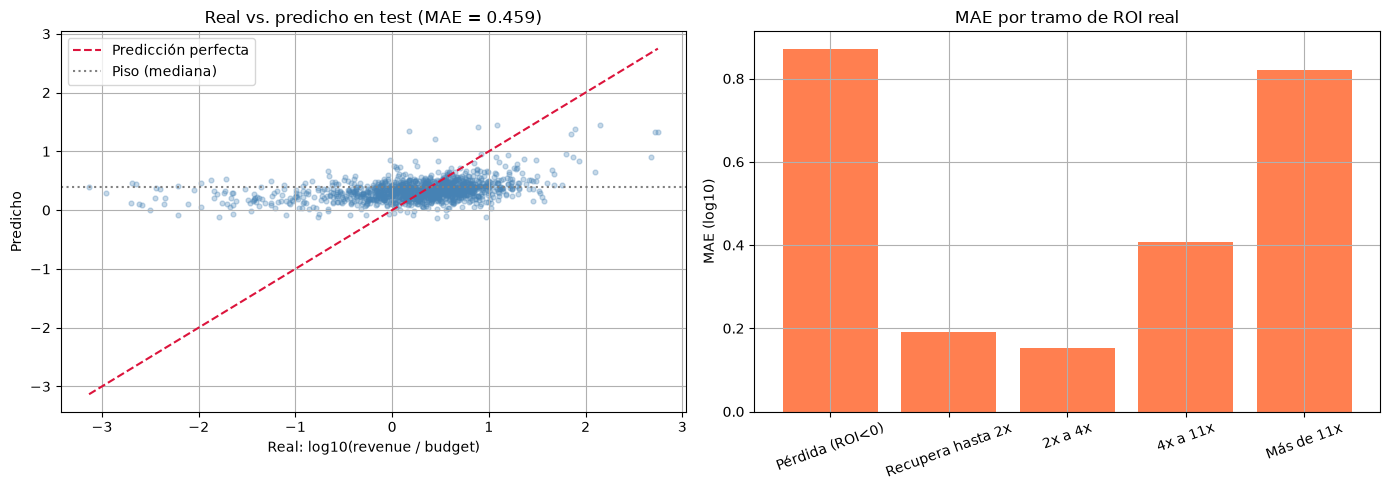

In [13]:
# 13. Dónde se equivoca: real vs. predicho y error por tramo del objetivo
res = test[["title", "release_year", "budget", "revenue", "roi", "vote_average", "vote_count"]].copy()
res["y_real"], res["y_pred"] = y_test.values, pred_test
res["roi_pred"] = 10 ** res["y_pred"] - 1
res["error_abs"] = (res["y_real"] - res["y_pred"]).abs()
res["tramo"] = pd.cut(res["roi"], [-1.01, 0, 1, 3, 10, np.inf],
                      labels=["Pérdida (ROI<0)", "Recupera hasta 2x", "2x a 4x", "4x a 11x", "Más de 11x"])
por_tramo = res.groupby("tramo", observed=True).agg(
    películas=("y_real", "size"), MAE=("error_abs", "mean"),
    ROI_real_mediano=("roi", "median"), ROI_predicho_mediano=("roi_pred", "median"),
    sesgo=("y_pred", lambda s: (s - res.loc[s.index, "y_real"]).mean()))
print(por_tramo.round(3).to_string())
print("\n(sesgo > 0: el modelo predice de más; sesgo < 0: predice de menos)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(res["y_real"], res["y_pred"], alpha=0.3, s=12, color="steelblue")
lim = [res["y_real"].min(), res["y_real"].max()]
axes[0].plot(lim, lim, color="crimson", linestyle="--", label="Predicción perfecta")
axes[0].axhline(piso.predict(X_test[:1])[0], color="gray", linestyle=":", label="Piso (mediana)")
axes[0].set_xlabel("Real: log10(revenue / budget)")
axes[0].set_ylabel("Predicho")
axes[0].set_title(f"Real vs. predicho en test (MAE = {mae_final:.3f})")
axes[0].legend()
axes[1].bar(por_tramo.index.astype(str), por_tramo["MAE"], color="coral")
axes[1].set_title("MAE por tramo de ROI real")
axes[1].set_ylabel("MAE (log10)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [14]:
# 14. Casos concretos: los errores más grandes del test
cols = ["title", "release_year", "budget", "revenue", "roi", "roi_pred"]
print("=== Predijo mucho más de lo que pasó (fracasos no anticipados) ===")
print(res.assign(e=res["y_pred"] - res["y_real"]).nlargest(5, "e")[cols].round(2).to_string(index=False))
print("\n=== Predijo mucho menos de lo que pasó (éxitos no anticipados) ===")
print(res.assign(e=res["y_real"] - res["y_pred"]).nlargest(5, "e")[cols].round(2).to_string(index=False))

=== Predijo mucho más de lo que pasó (fracasos no anticipados) ===
       title  release_year         budget     revenue     roi  roi_pred
  Hellraiser          2022  14000000.0000  10303.0000 -1.0000    1.4400
  Red Notice          2021 160000000.0000 178143.0000 -1.0000    0.9800
  The Killer          2023 175000000.0000 362113.0000 -1.0000    1.8600
The Gray Man          2022 200000000.0000 454023.0000 -1.0000    1.7800
 Tin Soldier          2025  45000000.0000  89572.0000 -1.0000    0.3200

=== Predijo mucho menos de lo que pasó (éxitos no anticipados) ===
                   title  release_year       budget        revenue      roi  roi_pred
        Secret Superstar          2017  286284.0000 137416709.0000 479.0000    7.1500
Dragon Ball Super: Broly          2018 1000000.0000 125002821.0000 124.0000    3.5300
              Avengement          2019 2400000.0000  89900000.0000  36.4600    0.4100
            Animal World          2018  125000.0000  69885700.0000 558.0900   20.6700
   

### En qué se apoya: importancia por permutación

Se desordena una columna por vez en el test y se mide cuánto sube el MAE. Si sube mucho, el modelo depende de esa columna.

                            aumento del MAE  desvío
budget                               0.0362  0.0039
director_popularity                  0.0056  0.0015
original_language                    0.0054  0.0006
runtime                              0.0052  0.0022
primary_production_company           0.0046  0.0010
primary_genre                        0.0041  0.0009
lead_actor_popularity                0.0025  0.0009
secondary_genre                      0.0024  0.0005
co_star_popularity                   0.0021  0.0010
release_month                        0.0018  0.0005
co_production_company                0.0015  0.0006
release_day_of_week                  0.0011  0.0011
release_year                         0.0000  0.0000


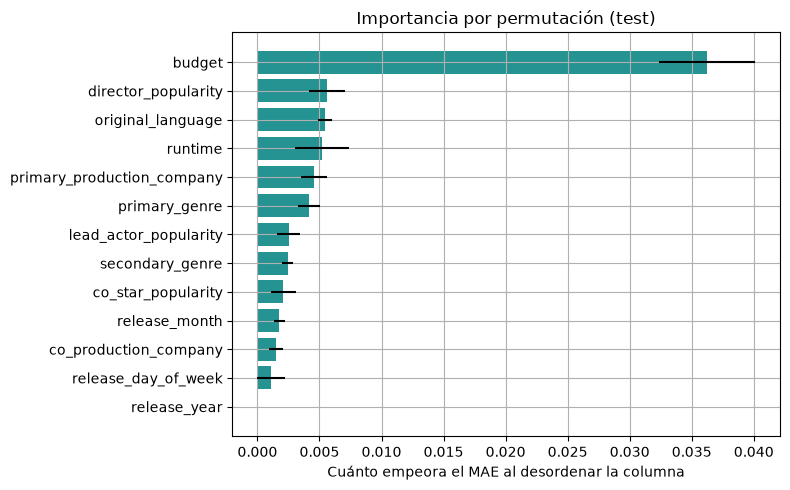

In [15]:
# 15. Importancia por permutación sobre el test
imp = permutation_importance(final, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=20, random_state=SEED, n_jobs=-1)
importancia = pd.DataFrame({"aumento del MAE": imp.importances_mean, "desvío": imp.importances_std},
                           index=FEATURES).sort_values("aumento del MAE", ascending=False)
print(importancia.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
orden = importancia.iloc[::-1]
ax.barh(orden.index, orden["aumento del MAE"], xerr=orden["desvío"], color="teal", alpha=0.85)
ax.set_title("Importancia por permutación (test)")
ax.set_xlabel("Cuánto empeora el MAE al desordenar la columna")
plt.tight_layout()
plt.show()

### ¿La columna que más pesa es una fuga?

`budget` es la que más pesa, y conviene sospechar porque también está en el denominador del objetivo. No es una fuga: el presupuesto se conoce **antes** de filmar, y el modelo lo va a tener siempre que se use. Lo que aprende es real: a igual recaudación relativa esperada, las películas caras necesitan recaudar mucho más para multiplicar su costo.

La sospecha de verdad está en las **popularidades**: TMDb devuelve la popularidad de la persona *hoy*, no la que tenía antes del rodaje. Si una película fue un éxito, su director y su elenco quedan más populares. Dos controles:

In [16]:
# 16. Control de fuga en las popularidades
# a) ¿Las popularidades se asocian con el éxito ex post (vote_count)? Spearman sobre entrenamiento.
cols_pop = ["director_popularity", "lead_actor_popularity", "co_star_popularity"]
print("Spearman con vote_count (éxito después del estreno):")
print(train[cols_pop + ["vote_count"]].corr(method="spearman")["vote_count"][cols_pop].round(3).to_string())

# b) ¿Cuánto cambia el test si se sacan? Mismo modelo, sin las tres columnas.
sin_pop = modelo(RandomForestRegressor(**mejor_rf), excluir=cols_pop).fit(X_train, y_train)
mae_sin_pop = mean_absolute_error(y_test, sin_pop.predict(X_test))
print(f"\nMAE test con popularidades: {mae_final:.4f} | sin popularidades: {mae_sin_pop:.4f} | "
      f"diferencia: {mae_sin_pop - mae_final:+.4f}")

Spearman con vote_count (éxito después del estreno):
director_popularity     0.3290
lead_actor_popularity   0.3440
co_star_popularity      0.3330



MAE test con popularidades: 0.4585 | sin popularidades: 0.4584 | diferencia: -0.0001


### Auditoría con la crítica del público (columnas post-estreno)

`vote_average` no entró al modelo. Ahora se usa para auditar: si las películas a las que el modelo les predijo mejor ROI también fueron mejor recibidas, el modelo capta algo de "calidad comercial" y no solo tamaño.

In [17]:
# 17. Validación post-predicción con vote_average
res["cuartil_pred"] = pd.qcut(res["y_pred"], 4, labels=["Q1 (peor ROI predicho)", "Q2", "Q3", "Q4 (mejor ROI predicho)"])
print(res.groupby("cuartil_pred", observed=True).agg(
    películas=("roi", "size"), ROI_real_mediano=("roi", "median"),
    vote_average_medio=("vote_average", "mean")).round(3).to_string())
print(f"\nSpearman(ROI predicho, vote_average) = {res['y_pred'].corr(res['vote_average'], method='spearman'):.3f}")
print(f"Spearman(ROI real, vote_average)     = {res['y_real'].corr(res['vote_average'], method='spearman'):.3f}")

                         películas  ROI_real_mediano  vote_average_medio
cuartil_pred                                                            
Q1 (peor ROI predicho)         320            0.2590              6.4530
Q2                             319            0.9030              6.6770
Q3                             319            1.5830              6.7740
Q4 (mejor ROI predicho)        320            2.7240              6.9580

Spearman(ROI predicho, vote_average) = 0.256
Spearman(ROI real, vote_average)     = 0.355


## 9. Transparencia: cuántas veces se miró el test

El test se miró **dos veces**. En la primera corrida, los errores más grandes eran películas con recaudaciones imposibles (*Memoir of a Snail* con 7 USD, *Society of the Snow* con 1.281 USD). Por eso se agregó el filtro `revenue >= 10.000 USD` y se volvió a correr.

Por qué lo consideramos aceptable, y por qué igual lo decimos:
- No cambió el modelo, los hiperparámetros ni las columnas: es una limpieza de montos imposibles, con el mismo umbral que ya se usaba para `budget`.
- El problema también estaba en el entrenamiento: hay recaudaciones menores a 10.000 USD en películas de 1971, 1985, 1999, 2006, 2009 y otros años. Se podía detectar sin mirar el test.
- Saca 22 películas de 6.522.
- Aun así, el número de test quedó un poco menos "virgen" de lo que debería. Para la Entrega 4 la limpieza queda fija y el test no se vuelve a tocar.

## 10. Guía de defensa (las preguntas del instructivo, con nuestros números)

**Qué cambió desde la Entrega 2 (minuto 0–2)**
- Dataset nuevo: el DAG en modo `full` dio 9.940 películas; quedan 6.391 con montos válidos y estrenadas antes de 2026.
- El objetivo sigue siendo el ROI, pero se modela y se mide como $\log_{10}(\text{revenue}/\text{budget})$.
- `revenue`, `vote_average` y `vote_count` quedan fuera del modelo. Los votos se usan solo para auditar.

**1. ¿Por qué esa métrica?**
MAE sobre el log del múltiplo `revenue/budget`. El error caro es equivocarse en *cuántas veces* recupera su costo una película, y eso es relativo: el log hace que un error de "el doble" pese igual en una película chica que en una grande. Con el ROI crudo, *Paranormal Activity* (ROI ≈ 12.900) lleva un fold a MAE 17,8 cuando los demás dan entre 3,8 y 7,3. El desvío entre folds (5,3) tapa cualquier diferencia entre modelos. Un MAE de 0,46 se lee como "en promedio le erra al múltiplo por un factor de 2,9".

**2. ¿Cuánto le gana al piso? ¿Es mucho o poco?**
- Validación: piso 0,426, Random Forest ajustado 0,381. Gana en los 5 folds; la mejora media (0,046) es mayor que su desvío (0,040).
- Test (2017–2025): piso 0,493 (factor 3,1), modelo 0,459 (factor 2,9). Es **7% menos error**.
- Es **poco**. Sirve para ordenar proyectos (el cuartil con mejor ROI predicho tuvo ROI real mediano de 2,7, contra 0,26 del peor cuartil), pero no para prometer un número. El ROI depende mucho de cosas que no están antes del estreno: la crítica, la competencia, si va a cines o a streaming.

**3. ¿Por qué la validación se arma así? ¿Qué pasaría al azar?**
El modelo se usaría con películas futuras, así que se entrena con el pasado y se valida con lo que sigue (`TimeSeriesSplit`, test = 20% más reciente). Además, las filas se repiten por entidad: productora, director, franquicia. Al azar, el MAE del Random Forest baja de 0,388 a 0,371 y el desvío entre folds cae de 0,027 a 0,006. Daría un número más lindo y una seguridad falsa: mezcla épocas y deja secuelas y productoras de los dos lados.

**4. ¿Por qué ese modelo y no uno más complejo o más simple?**
- Ridge (lineal, el simple) le gana al piso en 3 de 5 folds; en los dos folds más recientes es peor que el piso.
- Random Forest le gana a Ridge en los **5 de 5 folds** (sin ajustar: mejora 0,017 ± 0,010; ajustado: 0,024 ± 0,007). La mejora supera el ruido, así que se justifica la complejidad.
- HistGradientBoosting no le gana a Ridge por más que el ruido (0,005 ± 0,017), y Random Forest le gana a HGB en 4 de 5 folds.
- Ajuste: la curva es bastante plana (MAE entre 0,381 y 0,389). Lo que más importa es `max_features = 0,3`: que cada corte mire solo una parte de las columnas. El mejor es `min_samples_leaf = 5`.
- La comparación se hace **fold contra fold**. El desvío de cada modelo por separado mezcla lo difícil de cada época, que afecta igual a todos.

**5. Una confusión concreta, explicada desde el dominio**
- El tramo donde más erra son las **pérdidas**: le predice ROI positivo (≈ 0,85) a películas que perdieron plata. Los peores casos son *Red Notice* (2021), *The Gray Man* (2022) y *The Killer* (2023): presupuestos de 160 a 200 millones y recaudación menor a medio millón. Son **películas de Netflix**: se estrenaron casi directo en streaming, y TMDb registra solo la taquilla de cines. El modelo no tiene ninguna columna que diga "va a streaming". Para él, una película de acción de 200 millones con estrellas es un tanque de cine.
- En el otro extremo, subestima los fenómenos: a las películas con ROI mayor a 11x les predice ≈ 1,9 (*Secret Superstar*, *Dragon Ball Super: Broly*). El modelo aprende a ir hacia la mediana: es bueno en el medio (MAE 0,15–0,19 entre ROI 0 y 4) y malo en las puntas.
- Idea para la Entrega 4: una columna de tipo de distribución, o sacar del alcance los estrenos de streaming.

**6. La columna que más pesa, y qué hicimos para descartar una fuga**
- `budget` es la que más pesa: al desordenarla, el MAE de test sube 0,036. Sin ella, el MAE de validación empeora 0,017. No es fuga: se conoce antes de filmar. Lo que aprende es que las películas caras rara vez multiplican mucho su costo.
- La sospecha real está en las **popularidades**: TMDb da la popularidad de *hoy*, y se correlacionan con `vote_count` (Spearman ≈ 0,33). Es decir, están contaminadas por el éxito posterior. Pero sacarlas no cambia nada: el test pasa de 0,4585 a 0,4584 y la validación empeora apenas 0,0015. El resultado no se apoya en esa posible fuga. Para la Entrega 4 conviene sacarlas.

**Columnas que probamos y no sirvieron** (MAE de validación, con todas = 0,3807):
- `release_year`: importancia 0, y sin ella el MAE mejora (0,3794). Un bosque no puede extrapolar a años que no vio.
- `co_production_company` y `release_day_of_week`: importancia casi nula (≤ 0,0015).
- `original_language` (0,0008), productoras (0,0014), popularidades (0,0015) y `runtime` (0,0015): aportan menos que el desvío.
- Lo que más aporta después del presupuesto: el calendario (0,0035) y los géneros (0,0024).

**Lo que probamos y no anduvo**
- MAE sobre el ROI crudo (sección 3).
- HistGradientBoosting: no mejoró al Random Forest.
- En el período más reciente de validación (2012–2017), ningún modelo sin ajustar le ganó al piso. El negocio cambió (franquicias, streaming) y lo aprendido de los 90 transfiere peor. Por eso el MAE de test (0,459) es más alto que el de validación (0,381).

**Lo que nos marcaron en la Entrega 2:** *(completar con la devolución del docente)*